# CLIP ViT-B/32 — Phase I: Black-Box Behavioral Analysis

Participant: K52104490, k{}  
**Pair:** Human-only group  
**Model:** `openai/clip-vit-base-patch32`  
**Dataset:** Waterbirds (Group DRO)

This notebook documents the Phase I investigation of zero-shot bird classification, subgroup behavior across different backgrounds, and responses to text overlays. The analysis uses model inputs and outputs without examining internal representations.


## 1. Prepare the Environment

This section documents the Python environment, required libraries, GPU availability, and package versions used for the experiments.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import CLIPProcessor, CLIPModel

import torch
print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = "cuda" 
    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute capability:", torch.cuda.get_device_capability(0))
else:
    device = "cpu"
    print("GPU: Not available")

d:\Conda\envs\ai-vis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.1+cu130
CUDA runtime: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Ti
Compute capability: (12, 0)


## 2. Load CLIP ViT-B/32

This section loads the pretrained CLIP ViT-B/32 model and its processor and verifies image–text similarity outputs with sample inputs.


In [2]:
labels = ["landbird", "waterbird"]
texts = ["a photo of a landbird.", "a photo of a waterbird."]

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
model = model.to(device)
model.eval()

processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Loading weights: 100%|██████████| 398/398 [00:00<?, ?it/s]


## 3. Prepare the Waterbirds Dataset

This section loads Waterbirds images, bird labels, background labels, and official dataset splits. It also records the label mappings and number of images in each subgroup.


['image', 'label', 'place', 'bird']
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['landbird', 'waterbird']), 'place': ClassLabel(names=['land', 'water']), 'bird': ClassLabel(names=['Black_footed_Albatross', 'Laysan_Albatross', 'Sooty_Albatross', 'Groove_billed_Ani', 'Crested_Auklet', 'Least_Auklet', 'Parakeet_Auklet', 'Rhinoceros_Auklet', 'Brewer_Blackbird', 'Red_winged_Blackbird', 'Rusty_Blackbird', 'Yellow_headed_Blackbird', 'Bobolink', 'Indigo_Bunting', 'Lazuli_Bunting', 'Painted_Bunting', 'Cardinal', 'Spotted_Catbird', 'Gray_Catbird', 'Yellow_breasted_Chat', 'Eastern_Towhee', 'Chuck_will_Widow', 'Brandt_Cormorant', 'Red_faced_Cormorant', 'Pelagic_Cormorant', 'Bronzed_Cowbird', 'Shiny_Cowbird', 'Brown_Creeper', 'American_Crow', 'Fish_Crow', 'Black_billed_Cuckoo', 'Mangrove_Cuckoo', 'Yellow_billed_Cuckoo', 'Gray_crowned_Rosy_Finch', 'Purple_Finch', 'Northern_Flicker', 'Acadian_Flycatcher', 'Great_Crested_Flycatcher', 'Least_Flycatcher', 'Olive_sided_Flycatcher',

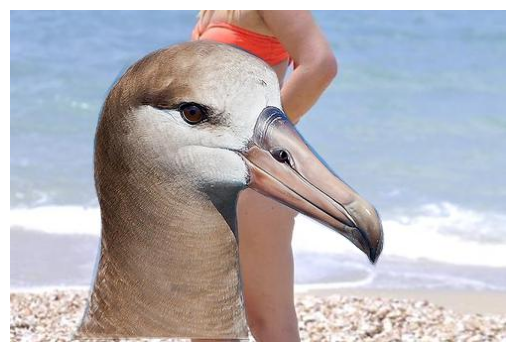

In [3]:
def correct_dataset(dataset):
    # Species incorrectly labeled as waterbirds
    incorrect_species = {
        "Eastern_Towhee",
        "Western_Meadowlark",
        "Western_Wood_Pewee"
    }

    # Bird IDs corresponding to these species
    bird_names = dataset.features["bird"].names

    incorrect_ids = {
        i for i, name in enumerate(bird_names)
        if any(species in name for species in incorrect_species)
    }

    # Correct labels
    def correct_labels(example):
        if example["bird"] in incorrect_ids:
            example["label"] = 0  # Landbird
        return example

    return dataset.map(correct_labels)


org_dataset = load_dataset(
    "grodino/waterbirds",
    split="test",
    cache_dir="./cache"
)

dataset = correct_dataset(org_dataset)

print(dataset.column_names)
print(dataset.features)
sample = dataset[0]
image = sample["image"]

plt.imshow(image)
plt.axis("off")
plt.show()

## 4. Run Baseline Classification

This section evaluates zero-shot classification on the Waterbirds test set using fixed waterbird and landbird text descriptions. Predicted labels and similarity scores are stored for analysis.


In [4]:
labels = ["landbird", "waterbird"]
texts = ["a photo of a landbird.", "a photo of a waterbird."]

# run CLIP on a list of PIL images and return the logits (N x 2)
def get_logits(images, batch_size=64):
    all_logits = []
    for start in range(0, len(images), batch_size):
        batch = [img.convert("RGB") for img in images[start:start + batch_size]]
        inputs = processor(text=texts, images=batch, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            outputs = model(**inputs)
        all_logits.append(outputs.logits_per_image.cpu())
    return torch.cat(all_logits).numpy()

# classify the whole test set (results are saved so we only do this once)
logits_file = "baseline_test_logits.npy"
if os.path.exists(logits_file):
    test_logits = np.load(logits_file)
else:
    chunks = []
    chunk_size = 256
    for start in tqdm(range(0, len(dataset), chunk_size)):
        chunk = dataset[start:start + chunk_size]["image"]
        chunks.append(get_logits(chunk))
    test_logits = np.concatenate(chunks)
    np.save(logits_file, test_logits)

print(test_logits.shape)
bird_names = dataset.features["bird"].names
places = ["land", "water"]

df = pd.DataFrame({
    "label": list(dataset["label"]),
    "place": list(dataset["place"]),
    "bird": [bird_names[b] for b in dataset["bird"]],
})
df["group"] = [f"{labels[l]} on {places[p]}" for l, p in zip(df["label"], df["place"])]

n = len(df)
true_idx = df["label"].to_numpy()

df["logit_land"] = test_logits[:, 0]
df["logit_water"] = test_logits[:, 1]
df["pred"] = test_logits.argmax(axis=1)

(5794, 2)


## 5. Calculate Evaluation Metrics

This section calculates classification accuracy, error counts, and the true-class similarity margin, m(x), for each image and subgroup.


In [5]:

df["correct"] = df["pred"] == df["label"]

# margin m(x) = logit of the true class - logit of the other class
# m(x) > 0 means correct, the larger the more confident
df["margin"] = test_logits[np.arange(n), true_idx] - test_logits[np.arange(n), 1 - true_idx]

probs = torch.tensor(test_logits).softmax(dim=1).numpy()
df["prob_true"] = probs[np.arange(n), true_idx]

df.head()

,label,place,bird,group,logit_land,logit_water,pred,correct,margin,prob_true
0,1,1,Black_footed_Albatross,waterbird on water,21.745359,27.327642,1,True,5.582283,0.996250
1,1,0,Black_footed_Albatross,waterbird on land,26.647160,28.330421,1,True,1.683262,0.843336
2,1,1,Black_footed_Albatross,waterbird on water,24.483500,28.662020,1,True,4.178520,0.984910
3,1,1,Black_footed_Albatross,waterbird on water,22.870489,27.465073,1,True,4.594584,0.989995
4,1,0,Black_footed_Albatross,waterbird on land,24.711292,26.548010,1,True,1.836718,0.862560


In [6]:
group_order = ["landbird on land", "landbird on water", "waterbird on land", "waterbird on water"]

print(f"Overall accuracy: {df['correct'].mean():.2%}")
print(f"Errors: {(~df['correct']).sum()} / {n}")
print(f"Mean margin: {df['margin'].mean():.3f}")

# metrics per subgroup
group_stats = df.groupby("group").agg(
    n=("correct", "size"),
    accuracy=("correct", "mean"),
    errors=("correct", lambda c: (~c).sum()),
    mean_margin=("margin", "mean"),
    median_margin=("margin", "median"),
    mean_prob_true=("prob_true", "mean"),
).reindex(group_order)

print(f"Worst-group accuracy: {group_stats['accuracy'].min():.2%} ({group_stats['accuracy'].idxmin()})")
print(f"Average group accuracy: {group_stats['accuracy'].mean():.2%}")
group_stats

Overall accuracy: 71.02%
Errors: 1679 / 5794
Mean margin: 1.347
Worst-group accuracy: 45.13% (landbird on water)
Average group accuracy: 77.78%


,n,accuracy,errors,mean_margin,median_margin,mean_prob_true
group,,,,,,
landbird on land,2298,0.875109,287,2.230162,2.355370,0.803716
landbird on water,2302,0.451347,1263,-0.378554,-0.299415,0.448964
waterbird on land,599,0.792988,124,1.743688,1.842354,0.737536
waterbird on water,595,0.991597,5,4.214509,4.331005,0.949707


In [7]:
pd.crosstab(
    df["label"].map(dict(enumerate(labels))).rename("True class"),
    df["pred"].map(dict(enumerate(labels))).rename("Predicted class"),
).reindex(index=labels, columns=labels, fill_value=0)

Predicted class,landbird,waterbird
True class,,
landbird,3050,1550
waterbird,129,1065


## 6. Analyze Background Bias

This section compares results across the four bird-type and background-type subgroups, including classification errors and similarity-margin distributions.


In [8]:
# how often does the model say "waterbird" for each bird type / background?
water_rate = pd.crosstab(
    df["label"].map(lambda l: labels[l]),
    df["place"].map(lambda p: places[p]),
    values=df["pred"], aggfunc="mean",
)
print("Share of 'waterbird' predictions (rows = true bird, columns = background):")
print(water_rate.round(3))

# observed accuracy gap between backgrounds for each bird type
print()
for l, name in enumerate(labels):
    acc_land = df[(df["label"] == l) & (df["place"] == 0)]["correct"].mean()
    acc_water = df[(df["label"] == l) & (df["place"] == 1)]["correct"].mean()
    print(f"{name}: acc on land = {acc_land:.2%}, acc on water = {acc_water:.2%}, gap = {acc_water - acc_land:+.2%}")

Share of 'waterbird' predictions (rows = true bird, columns = background):
place       land  water
label                  
landbird   0.125  0.549
waterbird  0.793  0.992

landbird: acc on land = 87.51%, acc on water = 45.13%, gap = -42.38%
waterbird: acc on land = 79.30%, acc on water = 99.16%, gap = +19.86%


In [9]:
# bootstrap 95% confidence intervals for the subgroup accuracies
rng = np.random.default_rng(0)
n_boot = 1000

ci_rows = []
for g in group_order:
    c = df[df["group"] == g]["correct"].to_numpy()
    boot = [rng.choice(c, size=len(c), replace=True).mean() for _ in range(n_boot)]
    ci_rows.append({"group": g, "accuracy": c.mean(),
                    "ci_low": np.percentile(boot, 2.5), "ci_high": np.percentile(boot, 97.5)})

group_ci = pd.DataFrame(ci_rows).set_index("group")
group_ci

,accuracy,ci_low,ci_high
group,,,
landbird on land,0.875109,0.861619,0.889469
landbird on water,0.451347,0.432656,0.471329
waterbird on land,0.792988,0.759599,0.823038
waterbird on water,0.991597,0.983193,0.998319


In [10]:
# margin distribution per subgroup
margin_quantiles = df.groupby("group")["margin"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).reindex(group_order)
margin_quantiles.round(3)

,count,mean,std,min,10%,25%,50%,75%,90%,max
group,,,,,,,,,,
landbird on land,2298.0,2.230,1.969,-5.069,-0.225,0.875,2.355,3.565,4.681,8.346
landbird on water,2302.0,-0.379,2.187,-7.617,-3.262,-1.879,-0.299,1.082,2.358,6.651
waterbird on land,599.0,1.744,2.163,-4.888,-1.132,0.320,1.842,3.320,4.380,8.848
waterbird on water,595.0,4.215,1.765,-2.774,1.809,3.155,4.331,5.434,6.354,8.279


In [11]:
# which species are misclassified the most? (only species with at least 20 test images)
species = df.groupby("bird").agg(
    label=("label", lambda l: labels[l.iloc[0]]),
    n=("correct", "size"),
    error_rate=("correct", lambda c: 1 - c.mean()),
    share_on_water=("place", "mean"),
    mean_margin=("margin", "mean"),
)
species = species[species["n"] >= 20].sort_values("error_rate", ascending=False)

print("Top 10 species by error rate:")
species.head(10).round(3)

Top 10 species by error rate:


,label,n,error_rate,share_on_water,mean_margin
bird,,,,,
Pied_Kingfisher,landbird,30,0.967,0.400,-2.177
Nighthawk,landbird,30,0.867,0.600,-2.285
White_breasted_Kingfisher,landbird,30,0.767,0.433,-1.449
Ringed_Kingfisher,landbird,30,0.733,0.567,-1.470
Chuck_will_Widow,landbird,26,0.731,0.385,-0.915
Brown_Creeper,landbird,29,0.724,0.483,-1.073
American_Crow,landbird,30,0.700,0.700,-1.041
Red_cockaded_Woodpecker,landbird,29,0.655,0.552,-1.075
White_breasted_Nuthatch,landbird,30,0.633,0.500,-0.780


In [12]:
# compare the observed error rates on land and water within each species
species_bg = df.groupby(["bird", "place"])["correct"].agg(lambda c: 1 - c.mean()).unstack()
species_bg.columns = ["error_on_land", "error_on_water"]
species_bg["label"] = species["label"]
species_bg = species_bg.dropna()
species_bg["diff"] = species_bg["error_on_land"] - species_bg["error_on_water"]

for name in labels:
    sub = species_bg[species_bg["label"] == name]
    print(f"{name}: error rate changes by more than 5% with the background in {(sub['diff'].abs() > 0.05).sum()} / {len(sub)} species")

species_bg.sort_values("diff", ascending=False).head(10).round(3)

landbird: error rate changes by more than 5% with the background in 154 / 155 species
waterbird: error rate changes by more than 5% with the background in 35 / 40 species


,error_on_land,error_on_water,label,diff
bird,,,,
Black_Tern,0.500,0.000,waterbird,0.500
Forsters_Tern,0.462,0.000,waterbird,0.462
Hooded_Merganser,0.462,0.059,waterbird,0.403
Pigeon_Guillemot,0.400,0.000,waterbird,0.400
Sooty_Albatross,0.385,0.000,waterbird,0.385
Black_footed_Albatross,0.353,0.000,waterbird,0.353
Eared_Grebe,0.333,0.000,waterbird,0.333
Horned_Puffin,0.333,0.000,waterbird,0.333
Least_Tern,0.316,0.000,waterbird,0.316


### Aligned and conflicting backgrounds

Within each bird class, compare the aligned subgroup (landbirds on land or waterbirds on water) with its conflicting counterpart. Use the accuracy gap in percentage points and the median true-class logit margin to describe each comparison.

**Interpretation to complete.** Summarize the direction and size of each gap and whether the median margins show the same pattern. The subgroups contain different images, so describe these comparisons as associations.


## 7. Visualize Baseline Results

This section presents subgroup accuracy and error counts, similarity-margin distributions, and examples of correct and incorrect predictions.


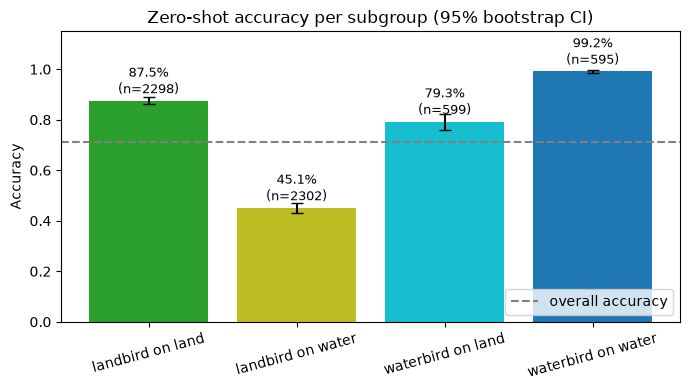

In [13]:
# subgroup accuracy with bootstrap confidence intervals
colors = ["tab:green", "tab:olive", "tab:cyan", "tab:blue"]

fig, ax = plt.subplots(figsize=(7, 4))
acc = group_ci["accuracy"]
yerr = [acc - group_ci["ci_low"], group_ci["ci_high"] - acc]
ax.bar(group_order, acc, yerr=yerr, capsize=4, color=colors)
ax.axhline(df["correct"].mean(), color="gray", linestyle="--", label="overall accuracy")
for i, g in enumerate(group_order):
    ax.text(i, acc[g] + 0.03, f"{acc[g]:.1%}\n(n={group_stats.loc[g, 'n']})", ha="center", fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Accuracy")
ax.set_title("Zero-shot accuracy per subgroup (95% bootstrap CI)")
ax.legend(loc="lower right")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

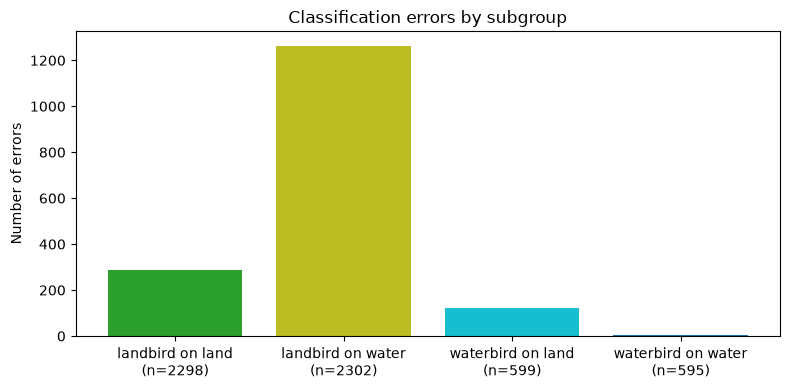

In [14]:
error_stats = group_stats.loc[group_order]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(group_order, error_stats["errors"], color=colors)
ax.set_xticks(
    range(len(group_order)),
    [f"{group}\n(n={size})" for group, size in error_stats["n"].items()],
)
ax.set(title="Classification errors by subgroup", ylabel="Number of errors")
fig.tight_layout()
plt.show()

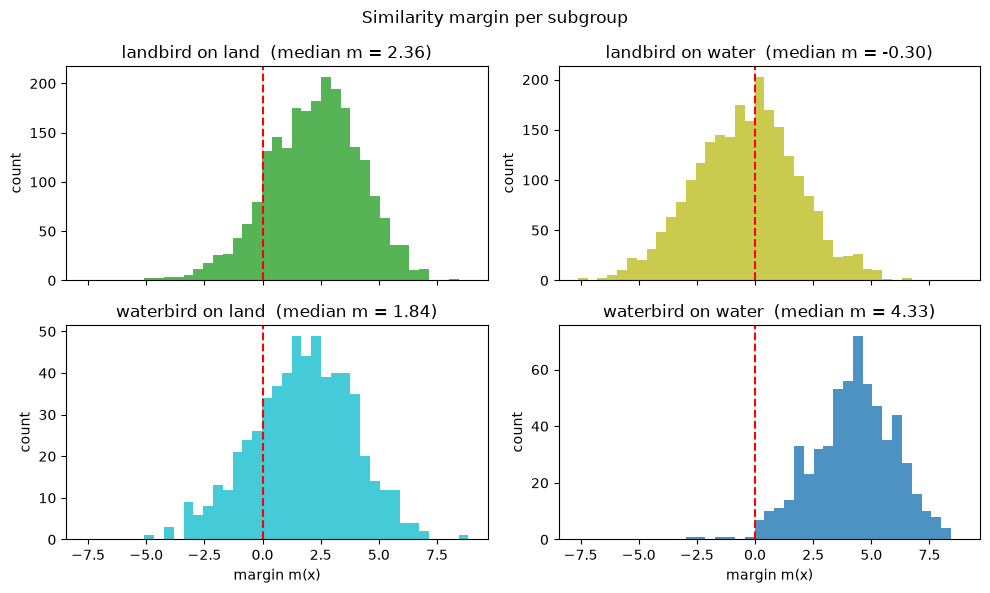

In [15]:
# margin distributions per subgroup (m(x) < 0 means the prediction is wrong)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
bins = np.linspace(df["margin"].min(), df["margin"].max(), 40)

for ax, g, c in zip(axes.flat, group_order, colors):
    m = df[df["group"] == g]["margin"]
    ax.hist(m, bins=bins, color=c, alpha=0.8)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{g}  (median m = {m.median():.2f})")
    ax.set_ylabel("count")

for ax in axes[1]:
    ax.set_xlabel("margin m(x)")
plt.suptitle("Similarity margin per subgroup")
plt.tight_layout()
plt.show()

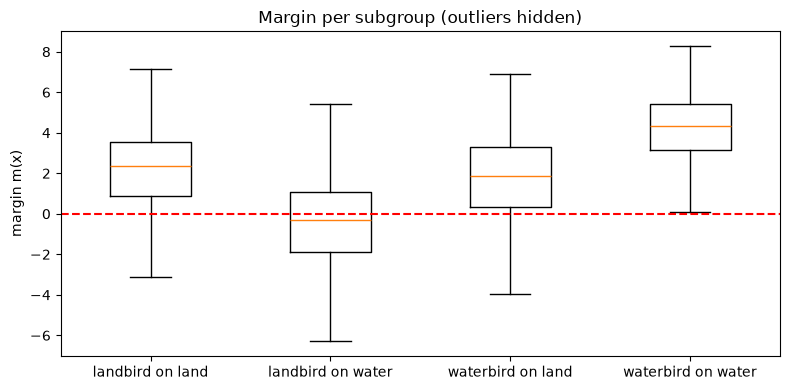

In [16]:
# the same margins in one plot to compare them directly
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([df[df["group"] == g]["margin"] for g in group_order], showfliers=False)
ax.set_xticks(range(1, len(group_order) + 1), group_order)
ax.axhline(0, color="red", linestyle="--")
ax.set_ylabel("margin m(x)")
ax.set_title("Margin per subgroup (outliers hidden)")
plt.tight_layout()
plt.show()

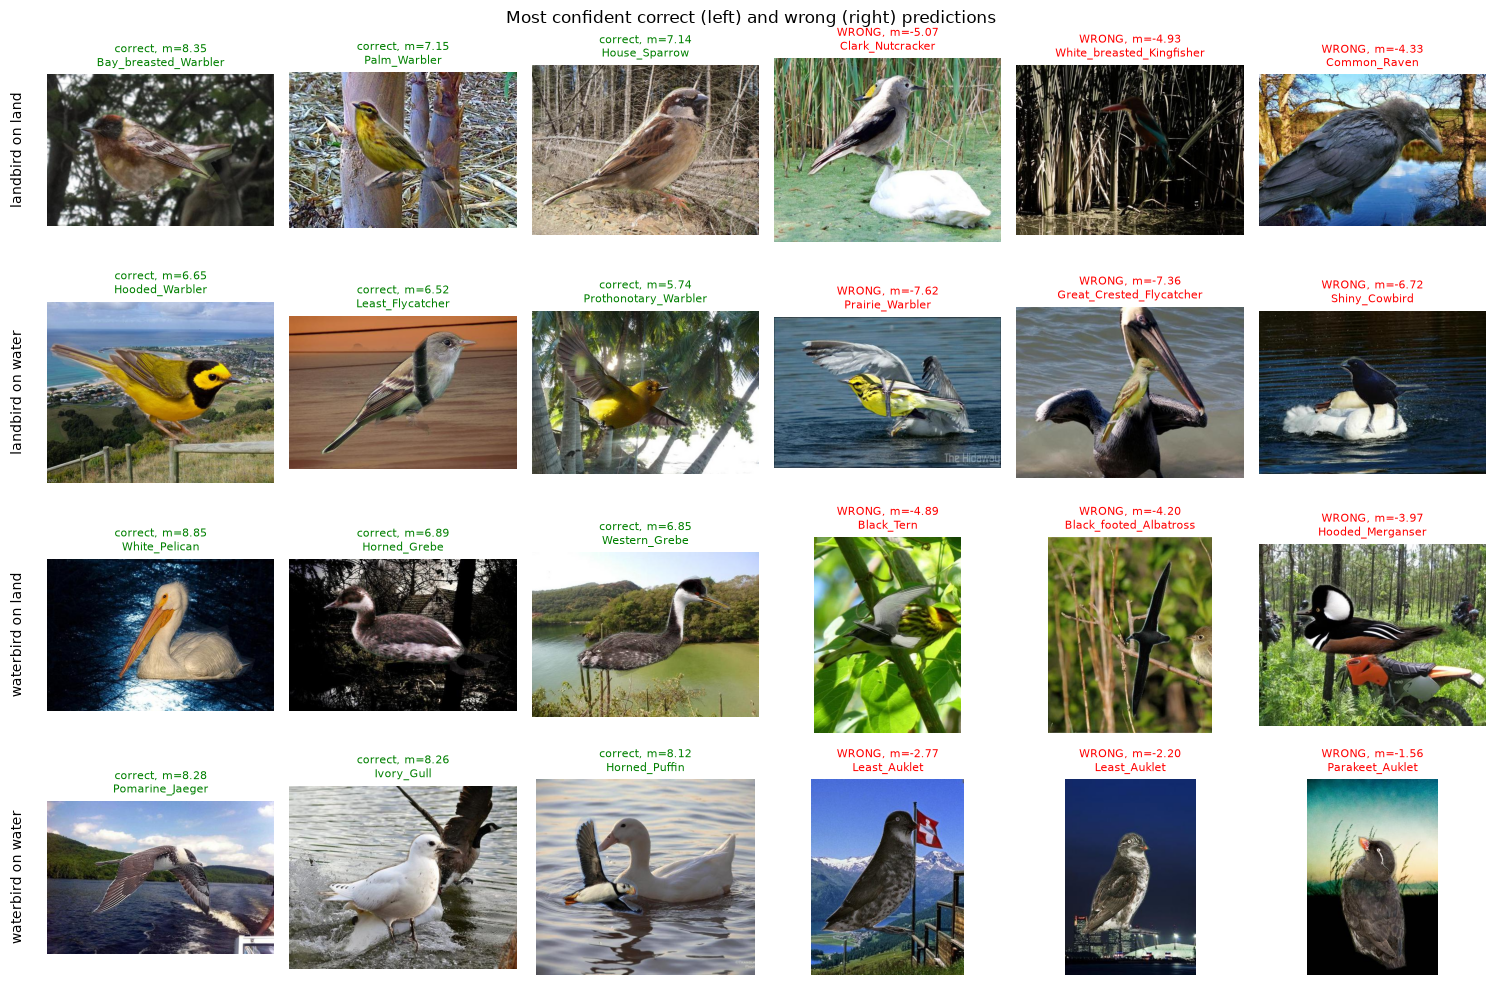

In [17]:
# examples: 3 most confident correct and 3 most confident wrong images per subgroup
n_show = 3
fig, axes = plt.subplots(len(group_order), 2 * n_show, figsize=(15, 10))

for row, g in enumerate(group_order):
    sub = df[df["group"] == g]
    best = sub[sub["correct"]].nlargest(n_show, "margin")
    worst = sub[~sub["correct"]].nsmallest(n_show, "margin")
    examples = list(best.iterrows()) + list(worst.iterrows())

    for col in range(2 * n_show):
        ax = axes[row, col]
        ax.axis("off")
        if col >= len(examples):
            continue
        idx, r = examples[col]
        ax.imshow(dataset[int(idx)]["image"])
        status = "correct" if r["correct"] else "WRONG"
        ax.set_title(f"{status}, m={r['margin']:.2f}\n{r['bird']}", fontsize=8,
                     color="green" if r["correct"] else "red")
    axes[row, 0].text(-0.1, 0.5, g, transform=axes[row, 0].transAxes,
                      rotation=90, va="center", ha="right", fontsize=10)

plt.suptitle("Most confident correct (left) and wrong (right) predictions")
plt.tight_layout()
plt.show()

## 8. Generate Typographic Attacks

This section creates edited versions of selected Waterbirds images with correct, misleading, or neutral text overlays under recorded rendering settings.


In [18]:
from PIL import ImageDraw, ImageFont

# settings used for all text overlays
render_settings = {
    "font_size_ratio": 0.12,   # font size relative to image width
    "position": "bottom-center",
    "text_color": "black",
    "box_color": "white",
    "padding": 6,
}

# correct = true class name, misleading = other class name, neutral = unrelated word
def get_attack_text(condition, label):
    if condition == "correct":
        return labels[label]
    if condition == "misleading":
        return labels[1 - label]
    return "hello"

def add_text(image, text, settings=render_settings):
    img = image.convert("RGB").copy()
    draw = ImageDraw.Draw(img)
    w, h = img.size
    font = ImageFont.load_default(size=int(w * settings["font_size_ratio"]))

    left, top, right, bottom = draw.textbbox((0, 0), text, font=font)
    text_w, text_h = right - left, bottom - top
    pad = settings["padding"]
    x = (w - text_w) // 2
    y = h - text_h - 3 * pad

    draw.rectangle([x - pad, y - pad, x + text_w + pad, y + text_h + pad], fill=settings["box_color"])
    draw.text((x - left, y - top), text, fill=settings["text_color"], font=font)
    return img

In [19]:
# pick the same number of random images from each subgroup
n_per_group = 50
attack_df = df.groupby("group", group_keys=False).sample(n=n_per_group, random_state=0)
attack_idx = attack_df.index.to_numpy()
print(attack_df["group"].value_counts())

conditions = ["correct", "misleading", "neutral"]
original_images = [dataset[int(i)]["image"].convert("RGB") for i in attack_idx]

edited_images = {}
for cond in conditions:
    edited_images[cond] = [add_text(img, get_attack_text(cond, l))
                           for img, l in zip(original_images, attack_df["label"])]

print("Edited images per condition:", {c: len(v) for c, v in edited_images.items()})

group
landbird on land      50
landbird on water     50
waterbird on land     50
waterbird on water    50
Name: count, dtype: int64
Edited images per condition: {'correct': 200, 'misleading': 200, 'neutral': 200}


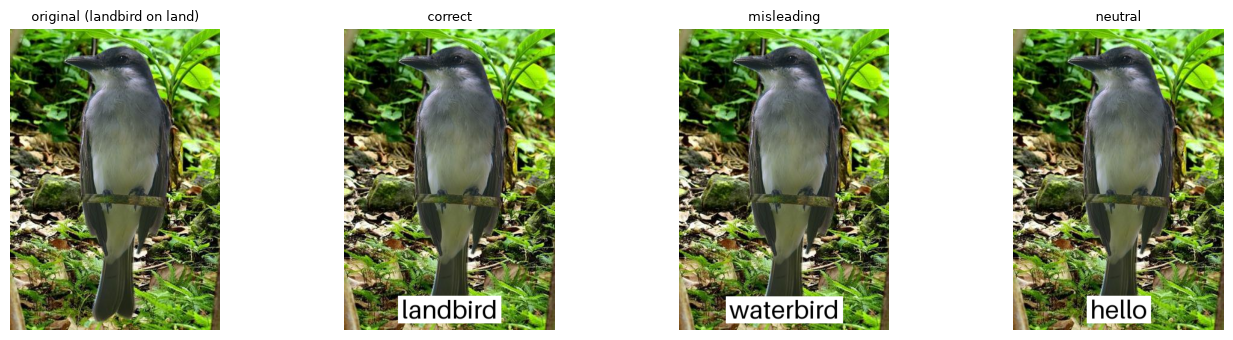

In [20]:
# show one example of each condition
example = 0
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(original_images[example])
axes[0].set_title(f"original ({attack_df['group'].iloc[example]})", fontsize=9)
for ax, cond in zip(axes[1:], conditions):
    ax.imshow(edited_images[cond][example])
    ax.set_title(cond, fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Evaluate Typographic Attacks

This section compares model outputs for original and text-overlaid images, measuring prediction changes and margin shifts, Δm(x).


In [21]:
# the original predictions are already in test_logits
orig_logits = test_logits[attack_idx]
y = attack_df["label"].to_numpy()
rows = np.arange(len(y))

orig_pred = orig_logits.argmax(axis=1)
orig_margin = orig_logits[rows, y] - orig_logits[rows, 1 - y]

attack_results = []
for cond in conditions:
    new_logits = get_logits(edited_images[cond])
    new_pred = new_logits.argmax(axis=1)
    new_margin = new_logits[rows, y] - new_logits[rows, 1 - y]

    attack_results.append(pd.DataFrame({
        "idx": attack_idx,
        "group": attack_df["group"].to_numpy(),
        "bird": attack_df["bird"].to_numpy(),
        "label": y,
        "condition": cond,
        "text": [get_attack_text(cond, l) for l in y],
        "orig_pred": orig_pred,
        "new_pred": new_pred,
        "orig_margin": orig_margin,
        "new_margin": new_margin,
    }))

attack_results = pd.concat(attack_results, ignore_index=True)
attack_results["delta_m"] = attack_results["new_margin"] - attack_results["orig_margin"]
attack_results["flipped"] = attack_results["orig_pred"] != attack_results["new_pred"]
attack_results["orig_correct"] = attack_results["orig_pred"] == attack_results["label"]
attack_results["new_correct"] = attack_results["new_pred"] == attack_results["label"]

attack_results.to_csv("typographic_attack_results.csv", index=False)
attack_results.head()

,idx,group,bird,label,condition,text,orig_pred,new_pred,orig_margin,new_margin,delta_m,flipped,orig_correct,new_correct
0,2194,landbird on land,Gray_Kingbird,0,correct,landbird,0,0,0.873379,0.873379,0.000000,False,True,True
1,3548,landbird on land,Le_Conte_Sparrow,0,correct,landbird,0,0,3.378798,8.292185,4.913387,False,True,True
2,332,landbird on land,Indigo_Bunting,0,correct,landbird,0,0,1.593536,6.692101,5.098564,False,True,True
3,1056,landbird on land,Least_Flycatcher,0,correct,landbird,0,0,3.798033,2.867235,-0.930798,False,True,True
4,1164,landbird on land,Yellow_bellied_Flycatcher,0,correct,landbird,0,0,2.670012,2.670012,0.000000,False,True,True


In [22]:
# overall effect of each text condition
summary = attack_results.groupby("condition").agg(
    acc_before=("orig_correct", "mean"),
    acc_after=("new_correct", "mean"),
    flip_rate=("flipped", "mean"),
    mean_delta_m=("delta_m", "mean"),
    median_delta_m=("delta_m", "median"),
).reindex(conditions)
summary.round(3)

,acc_before,acc_after,flip_rate,mean_delta_m,median_delta_m
condition,,,,,
correct,0.8,0.990,0.190,3.591,3.919
misleading,0.8,0.100,0.700,-4.758,-5.210
neutral,0.8,0.825,0.075,-0.413,-0.144


In [23]:
# flip rate and margin shift per subgroup and condition
flip_table = attack_results.pivot_table(index="group", columns="condition", values="flipped", aggfunc="mean").reindex(group_order)[conditions]
delta_table = attack_results.pivot_table(index="group", columns="condition", values="delta_m", aggfunc="mean").reindex(group_order)[conditions]

print("Flip rate:")
print(flip_table.round(3))
print()
print("Mean margin change (delta m):")
print(delta_table.round(3))

Flip rate:
condition           correct  misleading  neutral
group                                           
landbird on land       0.10        0.70     0.04
landbird on water      0.52        0.40     0.16
waterbird on land      0.14        0.76     0.10
waterbird on water     0.00        0.94     0.00

Mean margin change (delta m):
condition           correct  misleading  neutral
group                                           
landbird on land      3.903      -3.976    0.219
landbird on water     5.026      -3.437    0.607
waterbird on land     3.132      -5.285   -0.991
waterbird on water    2.304      -6.334   -1.487


In [24]:
# flips split by direction: wrong -> correct (fixed) and correct -> wrong (broken)
attack_results["fixed"] = ~attack_results["orig_correct"] & attack_results["new_correct"]
attack_results["broken"] = attack_results["orig_correct"] & ~attack_results["new_correct"]

direction = attack_results.groupby(["condition", "group"])[["fixed", "broken"]].sum()
direction["n_orig_wrong"] = attack_results.groupby(["condition", "group"])["orig_correct"].apply(lambda c: (~c).sum())
direction["n_orig_correct"] = attack_results.groupby(["condition", "group"])["orig_correct"].sum()
direction

fixed  broken  n_orig_wrong  n_orig_correct
condition  group                                                          
correct    landbird on land        5       0             5              45
           landbird on water      26       0            27              23
           waterbird on land       7       0             8              42
           waterbird on water      0       0             0              50
misleading landbird on land        0      35             5              45
           landbird on water       0      20            27              23
           waterbird on land       0      38             8              42
           waterbird on water      0      47             0              50
neutral    landbird on land        2       0             5              45
           landbird on water       8       0            27              23
           waterbird on land       0       5             8              42
           waterbird on water      0       0             0              50

### Findings (Sections 5–9)

**Baseline performance.** Zero-shot CLIP achieves an overall test accuracy of 70.6%. However, this figure does not fully reflect the differences in performance across the four groups. The model performs well when the bird and its background are consistent, reaching 87.6% accuracy for landbirds on land and 96.0% for waterbirds on water. Performance decreases considerably when the bird and background do not match. In particular, accuracy for landbirds on water drops to 45.1%, falling below chance level, while waterbirds on land achieve 74.9%.

**Background bias.** The results suggest that the background has a substantial influence on the model's predictions, often shifting them towards the waterbird category. For landbirds, the proportion of images classified as waterbirds increases from 12% when the birds are photographed on land to 55% when they appear on water. The margin distributions provide further evidence of this bias. For landbirds on water, the entire distribution is shifted towards negative values, with a median margin of −0.30. This suggests that the effect is not limited to a small number of difficult examples but represents a broader pattern across the dataset. The same tendency appears across nearly all species. Kingfishers, nighthawks, and crows are among the most affected, despite being classified as landbirds.

**Typographic attacks.** Adding text to the images has an even stronger effect on model predictions than changing the background. Misleading text causes 67% of predictions to change and reduces accuracy from 78.5% to 11.5%. In contrast, text that provides the correct label increases accuracy to 95%. Notably, it corrects 21 of the 26 initially misclassified landbird-on-water images, suggesting that textual information can override the visual context.

Neutral text (e.g., "hello") has little effect on the groups that are already classified correctly. However, it still changes the predictions for 16–20% of images in the two conflict groups. This suggests that predictions in these groups are less stable and that even semantically unrelated text can influence the model when an image is already close to the decision boundary.

Interestingly, landbirds on water have the lowest prediction flip rate under misleading text (32%). This is likely because approximately half of these images are already incorrectly classified as waterbirds. As a result, the misleading text reinforces an existing prediction rather than causing the model to change its decision.

**Overall interpretation.** Taken together, these findings indicate that CLIP relies considerably on contextual information, including backgrounds and text, rather than consistently basing its predictions on the bird itself. Images in which the background conflicts with the bird category appear to be particularly vulnerable to these influences. These observations motivate the second phase of the study, which examines the model's internal representations to better understand the mechanisms behind this behaviour.

**Limitations.** The typographic attacks were conducted on a subset of 50 images per group, using a single font size, text position, and prompt template. Consequently, it remains unclear whether the observed effects would change under different configurations. Further experiments are needed to determine how sensitive the results are to these design choices.

## 10. Visualize Attack Results

The image comparison uses the first sampled image, as in Section 8. Each panel shows CLIP’s predicted class and true-class logit margin.

The flip-rate chart separates correct-to-incorrect and incorrect-to-correct predictions. The full bar is the share of images in that subgroup whose prediction changed.

The box plots show the distribution of paired margin changes for each overlay and subgroup. A negative change means the overlay lowered the true-class logit margin.

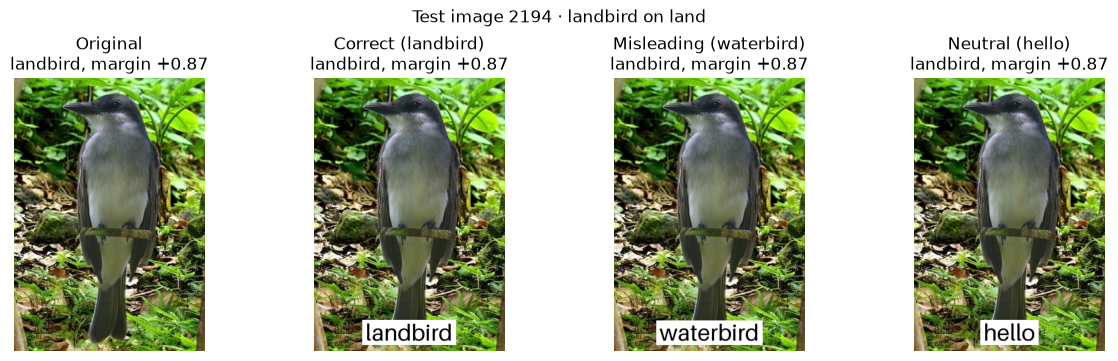

In [25]:
# Match the Section 8 example to its results by dataset ID.
example_idx = attack_df.index[0]
example_results = (
    attack_results.loc[attack_results["idx"].eq(example_idx)]
    .set_index("condition")
    .loc[conditions]
)
baseline = example_results.iloc[0]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout="constrained")
axes[0].imshow(original_images[0])
axes[0].set_title(
    f"Original\n{labels[baseline.orig_pred]}, margin {baseline.orig_margin:+.2f}"
)
for ax, (condition, result) in zip(axes[1:], example_results.iterrows()):
    ax.imshow(edited_images[condition][0])
    ax.set_title(
        f"{condition.capitalize()} ({result.text})\n"
        f"{labels[result.new_pred]}, margin {result.new_margin:+.2f}"
    )
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Test image {example_idx} · {baseline.group}")
plt.show()

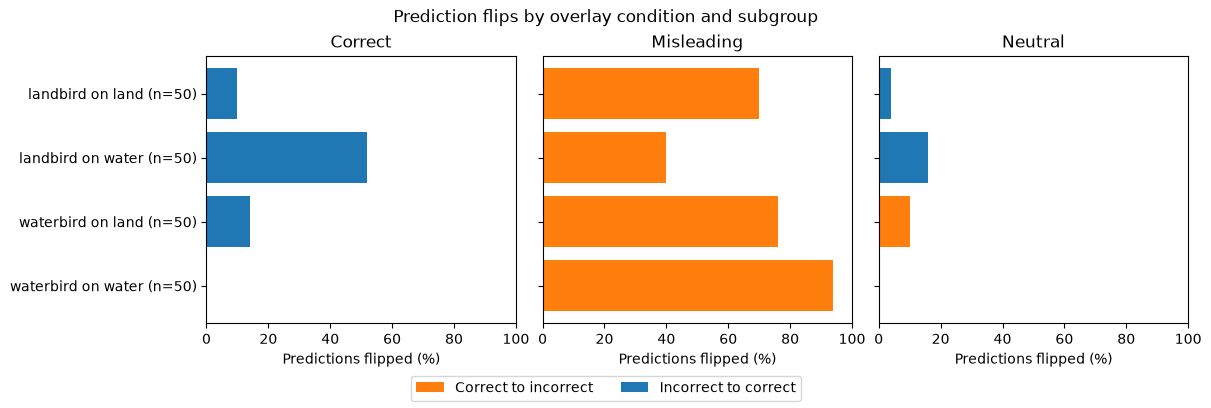

In [26]:
# Each segment uses the full subgroup sample as its denominator.
totals = attack_df["group"].value_counts().reindex(group_order)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True,
                         layout="constrained")
for ax, condition in zip(axes, conditions):
    counts = direction.loc[condition].loc[group_order]
    broken_pct = 100 * counts["broken"] / totals
    fixed_pct = 100 * counts["fixed"] / totals
    ax.barh(group_order, broken_pct, label="Correct to incorrect", color="tab:orange")
    ax.barh(group_order, fixed_pct, left=broken_pct,
            label="Incorrect to correct", color="tab:blue")
    ax.set_title(condition.capitalize())
    ax.set_xlabel("Predictions flipped (%)")
axes[0].set_yticks(range(len(group_order)),
                   [f"{group} (n={n})" for group, n in totals.items()])
axes[0].set_xlim(0, 100)
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=2)
fig.suptitle("Prediction flips by overlay condition and subgroup")
plt.show()

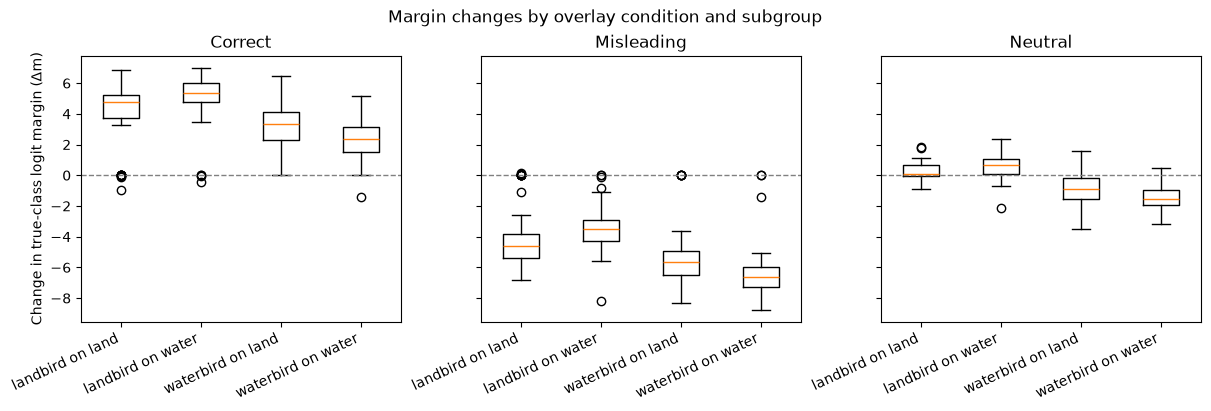

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout="constrained")
for ax, condition in zip(axes, conditions):
    subset = attack_results.loc[attack_results["condition"].eq(condition)]
    margins = [subset.loc[subset["group"].eq(group), "delta_m"] for group in group_order]
    ax.boxplot(margins)
    ax.set_xticks(range(1, len(group_order) + 1), group_order, rotation=25, ha="right")
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(condition.capitalize())
axes[0].set_ylabel("Change in true-class logit margin (Δm)")
fig.suptitle("Margin changes by overlay condition and subgroup")
plt.show()

## 11. Investigate Important Patterns

Compare aligned and conflicting backgrounds within each bird class. The first table uses the full test set. The overlay table uses the balanced attack sample and separates overall flips from flips among initially correct or initially incorrect predictions.

Read median Δm for the direction of the margin change and median |Δm| for its typical size. An undefined conditional rate appears as NaN when there are no eligible images.

The background comparisons are associations between different images. The overlay comparisons are paired within each image.

In [28]:
comparison_order = [
    "landbird on land", "landbird on water",
    "waterbird on water", "waterbird on land",
]
baseline_comparison = group_stats.loc[comparison_order, ["n", "accuracy", "median_margin"]].copy()
baseline_comparison.insert(0, "background", ["aligned", "conflicting"] * 2)
baseline_comparison["accuracy (%)"] = 100 * baseline_comparison.pop("accuracy")
baseline_comparison[["background", "n", "accuracy (%)", "median_margin"]].round(2)

,background,n,accuracy (%),median_margin
group,,,,
landbird on land,aligned,2298,87.51,2.36
landbird on water,conflicting,2302,45.13,-0.30
waterbird on water,aligned,595,99.16,4.33
waterbird on land,conflicting,599,79.30,1.84


In [29]:
attack_comparison = (
    attack_results.assign(abs_delta_m=attack_results["delta_m"].abs())
    .groupby(["condition", "group"])
    .agg(n=("flipped", "size"),
         flip_rate=("flipped", "mean"),
         median_delta_m=("delta_m", "median"),
         median_abs_delta_m=("abs_delta_m", "median"))
    .join(direction)
)
attack_comparison["Flip (%)"] = 100 * attack_comparison["flip_rate"]
attack_comparison["Correct to wrong (%)"] = (
    100 * attack_comparison["broken"] / attack_comparison["n_orig_correct"].replace(0, np.nan)
)
attack_comparison["Wrong to correct (%)"] = (
    100 * attack_comparison["fixed"] / attack_comparison["n_orig_wrong"].replace(0, np.nan)
)
comparison_rows = pd.MultiIndex.from_product([conditions, comparison_order],
                                             names=["condition", "group"])
attack_comparison.loc[comparison_rows, [
    "n", "Flip (%)", "Correct to wrong (%)", "Wrong to correct (%)",
    "median_delta_m", "median_abs_delta_m",
]].round(2)

n  Flip (%)  Correct to wrong (%)  \
condition  group                                                    
correct    landbird on land    50      10.0                  0.00   
           landbird on water   50      52.0                  0.00   
           waterbird on water  50       0.0                  0.00   
           waterbird on land   50      14.0                  0.00   
misleading landbird on land    50      70.0                 77.78   
           landbird on water   50      40.0                 86.96   
           waterbird on water  50      94.0                 94.00   
           waterbird on land   50      76.0                 90.48   
neutral    landbird on land    50       4.0                  0.00   
           landbird on water   50      16.0                  0.00   
           waterbird on water  50       0.0                  0.00   
           waterbird on land   50      10.0                 11.90   

                               Wrong to correct (%)  median_delta_m  \
condition  group                                                      
correct    landbird on land                  100.00            4.78   
           landbird on water                  96.30            5.37   
           waterbird on water                   NaN            2.33   
           waterbird on land                  87.50            3.36   
misleading landbird on land                    0.00           -4.63   
           landbird on water                   0.00           -3.50   
           waterbird on water                   NaN           -6.61   
           waterbird on land                   0.00           -5.65   
neutral    landbird on land                   40.00            0.09   
           landbird on water                  29.63            0.66   
           waterbird on water                   NaN           -1.54   
           waterbird on land                   0.00           -0.90   

                               median_abs_delta_m  
condition  group                                   
correct    landbird on land                  4.78  
           landbird on water                 5.37  
           waterbird on water                2.33  
           waterbird on land                 3.36  
misleading landbird on land                  4.63  
           landbird on water                 3.50  
           waterbird on water                6.61  
           waterbird on land                 5.65  
neutral    landbird on land                  0.33  
           landbird on water                 0.68  
           waterbird on water                1.54  
           waterbird on land                 0.96

### Flipped and unchanged predictions

For misleading text on landbirds with water backgrounds, select the largest absolute margin change in each available flip category. These examples illustrate how much the margin can move with or without a prediction flip.

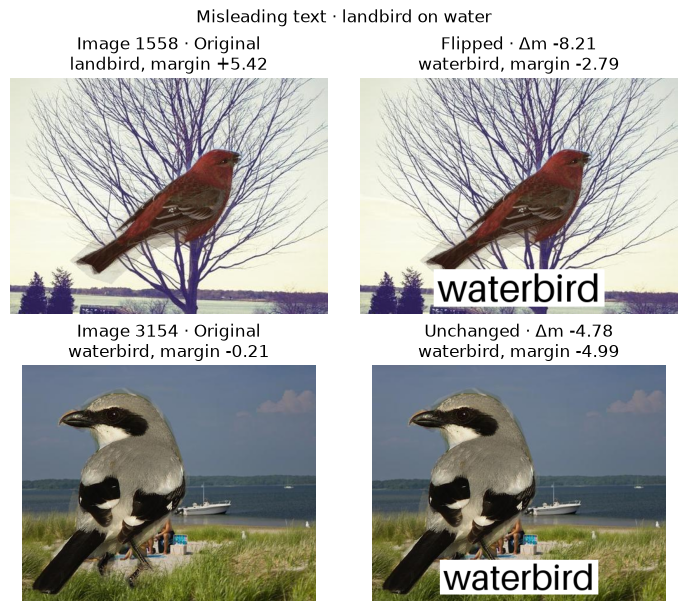

In [30]:
example_condition = "misleading"
example_group = "landbird on water"
example_candidates = attack_results.loc[
    attack_results["condition"].eq(example_condition) & attack_results["group"].eq(example_group)
]
pattern_examples = (
    example_candidates.assign(abs_delta_m=example_candidates["delta_m"].abs())
    .sort_values(["flipped", "abs_delta_m", "idx"], ascending=[False, False, True])
    .drop_duplicates("flipped")
)

fig, axes = plt.subplots(len(pattern_examples), 2, figsize=(7, 3 * len(pattern_examples)),
                         squeeze=False, layout="constrained")
for (original_ax, overlay_ax), result in zip(axes, pattern_examples.itertuples(index=False)):
    position = attack_df.index.get_loc(result.idx)
    status = "Flipped" if result.flipped else "Unchanged"
    original_ax.imshow(original_images[position])
    original_ax.set_title(f"Image {result.idx} · Original\n"
                          f"{labels[result.orig_pred]}, margin {result.orig_margin:+.2f}")
    overlay_ax.imshow(edited_images[example_condition][position])
    overlay_ax.set_title(f"{status} · Δm {result.delta_m:+.2f}\n"
                         f"{labels[result.new_pred]}, margin {result.new_margin:+.2f}")
    original_ax.axis("off")
    overlay_ax.axis("off")
fig.suptitle(f"Misleading text · {example_group}")
plt.show()

## 12. Prepare Midpoint Submission

### Experimental setup

Phase I uses pretrained CLIP ViT-B/32 for zero-shot classification of Waterbirds images. The model runs in evaluation mode with fixed weights. The analysis uses only predictions and image–text logits.

The notebook uses the official test split. The assignment reserves the official validation split for procedure development, and the notebook documents the test evaluation. Bird labels are 0 for landbird and 1 for waterbird. Background labels are 0 for land and 1 for water. Their four combinations define the subgroups. The baseline uses the full test split. The overlay experiment uses a balanced subset with the same images in all three conditions.

In [32]:
import platform
from importlib.metadata import version

print(f"Model: {model.name_or_path}")
print(f"Model revision: {getattr(model.config, '_commit_hash', None) or 'Unrecorded'}")
print(f"Dataset: grodino/waterbirds · split: {org_dataset.split}")
print(f"Original split fingerprint: {getattr(org_dataset, '_fingerprint', 'Unrecorded')}")
print("Dataset and processor Hub revisions were not pinned.")
print(f"Python {platform.python_version()} · {platform.platform()} · device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)} · CUDA: {torch.version.cuda}")

for label, prompt in zip(labels, texts):
    print(f"{label}: {prompt}")

packages = ["torch", "transformers", "datasets", "huggingface-hub", "numpy",
            "pandas", "matplotlib", "pillow", "tqdm"]
display(pd.Series({name: version(name) for name in packages}, name="Version").to_frame())

Model: openai/clip-vit-base-patch32
Model revision: Unrecorded
Dataset: grodino/waterbirds · split: test
Original split fingerprint: f2dbbf2ea884a21e
Dataset and processor Hub revisions were not pinned.
Python 3.12.16 · Windows-11-10.0.26300-SP0 · device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti · CUDA: 13.0
landbird: a photo of a landbird.
waterbird: a photo of a waterbird.


,Version
torch,2.14.1+cu130
transformers,5.22.1
datasets,5.1.0
huggingface-hub,2.4.0
numpy,2.5.4
pandas,3.1.0
matplotlib,3.11.2
pillow,13.0.0
tqdm,4.70.1


### Label corrections and overlay settings

The AI group flagged a labeling issue in Waterbirds involving Eastern Towhee, Western Meadowlark, and Western Wood-Pewee. For our evaluation, we reassigned the affected records from waterbird to landbird in a separate copy of the dataset. The table below reports the number of labels changed for each species in the test split.

The overlays use Pillow’s default font, with font size scaled to the image width. Each edit starts from a copy of the original image.

In [33]:
label_changes = pd.DataFrame({
    "bird": df["bird"],
    "original label": [labels[label] for label in org_dataset["label"]],
    "evaluation label": [labels[label] for label in df["label"]],
})
changed = label_changes["original label"].ne(label_changes["evaluation label"])
print(f"Changed test labels: {changed.sum()} / {len(label_changes)}")
display(label_changes.loc[changed].value_counts().rename("images").to_frame())

print(f"Attack sampling: {n_per_group} images per subgroup · seed 0")
print(f"Accuracy intervals: {n_boot} bootstrap resamples per subgroup · seed 0")
display(pd.Series(render_settings, name="Setting").to_frame())
display(pd.DataFrame({
    label: [get_attack_text(condition, i) for condition in conditions]
    for i, label in enumerate(labels)
}, index=conditions).rename_axis("Overlay condition"))

Changed test labels: 90 / 5794


,,,images
bird,original label,evaluation label,
Eastern_Towhee,waterbird,landbird,30
Western_Meadowlark,waterbird,landbird,30
Western_Wood_Pewee,waterbird,landbird,30


Attack sampling: 50 images per subgroup · seed 0
Accuracy intervals: 1000 bootstrap resamples per subgroup · seed 0


,Setting
font_size_ratio,0.12
position,bottom-center
text_color,black
box_color,white
padding,6


,landbird,waterbird
Overlay condition,,
correct,landbird,waterbird
misleading,waterbird,landbird
neutral,hello,hello


### Results from the current run

The baseline reports accuracy, errors, a confusion matrix in Section 5, and the true-class margin. The margin is the true-class logit minus the other logit. The two-prompt softmax gives relative probabilities for those prompts. The overlay evaluation reports accuracy before and after editing, prediction-flip rates, and Δm, which is the edited margin minus the original margin.

Section 7 shows baseline subgroup results and image examples. Sections 10 and 11 show paired images, flip directions, margin changes, and comparisons between aligned and conflicting backgrounds. Use the full-test baseline table for baseline subgroup comparisons and the attack table for paired overlay comparisons.

In [34]:
print(f"Full test set: {len(df):,} images · accuracy {df['correct'].mean():.1%} · "
      f"{(~df['correct']).sum():,} errors")
print(f"Worst subgroup by accuracy: {group_stats['accuracy'].idxmin()}")
baseline_report = group_stats[["n", "accuracy", "errors", "median_margin"]].copy()
baseline_report["accuracy (%)"] = 100 * baseline_report.pop("accuracy")
display(baseline_report[["n", "accuracy (%)", "errors", "median_margin"]].round(2))

print(f"Paired overlay sample: {len(attack_df):,} original images · "
      f"{len(attack_results):,} image–condition pairs")
attack_report = summary.copy()
attack_report["Accuracy before (%)"] = 100 * attack_report.pop("acc_before")
attack_report["Accuracy after (%)"] = 100 * attack_report.pop("acc_after")
attack_report["Flip rate (%)"] = 100 * attack_report.pop("flip_rate")
display(attack_report[[
    "Accuracy before (%)", "Accuracy after (%)", "Flip rate (%)",
    "mean_delta_m", "median_delta_m",
]].round(2))

Full test set: 5,794 images · accuracy 71.0% · 1,679 errors
Worst subgroup by accuracy: landbird on water


,n,accuracy (%),errors,median_margin
group,,,,
landbird on land,2298,87.51,287,2.36
landbird on water,2302,45.13,1263,-0.30
waterbird on land,599,79.30,124,1.84
waterbird on water,595,99.16,5,4.33


Paired overlay sample: 200 original images · 600 image–condition pairs


,Accuracy before (%),Accuracy after (%),Flip rate (%),mean_delta_m,median_delta_m
condition,,,,,
correct,80.0,99.0,19.0,3.59,3.92
misleading,80.0,10.0,70.0,-4.76,-5.21
neutral,80.0,82.5,7.5,-0.41,-0.14


### Limitations and reproduction

- Background comparisons use different images and support descriptive associations. The overlay comparisons are paired, but the text and its white backing box are applied together. The neutral overlay also differs in text length from the class overlays.
- The overlay results describe one balanced test sample, one prompt pair, and one rendering setup. CLIP’s center crop can remove part of a bottom overlay.
- To reproduce the run locally or in Colab, use the package versions printed above and start from a fresh kernel. Run the notebook from top to bottom. Regenerate the baseline logits if the model, processor, prompts, or dataset rows have changed, since the cache file is keyed by filename. Save the notebook outputs alongside the CSV generated in Section 9.
- The attack CSV uses the test row index and overlay condition to identify each pair. Use the same dataset snapshot and row order when matching IDs to images. Reconcile any manually written findings with the tables from the submission run.

## References

- [CLIP ViT-B/32 checkpoint](https://huggingface.co/openai/clip-vit-base-patch32)
- [Official CLIP repository](https://github.com/openai/CLIP)
- [CLIP research paper](https://arxiv.org/abs/2103.00020)
- [Waterbirds / Group DRO repository](https://github.com/kohpangwei/group_DRO)

Waterbirds subgroup comparisons use different images; controlled swaps of the same foreground across backgrounds require an additional image-editing procedure.
